# Alignment quality of the unmasked chr22 databank alignments

Sum-of-pairs score (cogent3 `sp_score`) in non-overlapping 1 kb windows of the
per-fragment Human/Chimpanzee/Orangutan alignments downloaded by `eti` for each
region in `DATA_DIRS` (currently `intergenicAR`, from
`HumChimpOranGor_10_114/intergenicAR/nonmaksed_alldata_chrm22`). Every `.fa` file at
the top level of the directory is read; subfolders (`logs/`, `md5/`, `not_completed/`)
are ignored. Windows are taken within each file, so none spans two fragments, and the
scores of all files are pooled into one distribution per region.

`sp_score` turns each pairwise genetic distance into an estimated number of
unchanged positions, subtracts an affine gap penalty (`gap_insert=12`, `gap_extend=1`
by default), and sums over the three species pairs. With 3 sequences and a 1 kb
window the maximum is 3000 (three identical, gap-free sequences); gap-dominated
windows go strongly negative.

**Short fragments are not scored.** The trailing partial window of each file is
dropped so that every score covers the same number of columns, which means a file
shorter than 1 kb contributes no windows. Compare `scored_length` with
`n_windows × 1000` in the summary table to see how much sequence this leaves out.

`frac_allgap_cols` reports the fraction of columns that are gaps in all three
species. `sp_score` skips such columns, so with `DROP_ALLGAP_COLUMNS = True` they are
removed with `omit_gap_pos()` before windowing and every window then holds 1 kb of
scorable columns. The databank alignments should contain few or none of them.

In [7]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from cogent3 import load_aligned_seqs, get_app

In [8]:
# region label -> directory of per-fragment .fa alignments (top level only; subfolders ignored)
DATA_DIRS = {
    "intergenicAR": "/xdisk/masel/uliseshmc/EstimatingUd/HumChimpOranGor_10_114/intergenicAR/nonmaksed_alldata_chrm22",
    "distalIG": "/xdisk/masel/uliseshmc/EstimatingUd/HumChimpOranGor_10_114/distalIG/nonmaksed_alldata_chrm22",
}
REGIONS = list(DATA_DIRS)
WINDOW = 1_000  # bp
DROP_ALLGAP_COLUMNS = False  # remove columns that are '-' in every species before windowing

# default sp_score settings; calc="pdist" avoids NaN distances on very divergent windows
sp_score = get_app("sp_score", calc="JC69", gap_insert=12.0, gap_extend=1.0)

In [9]:
def window_sp_scores(aln, window, app):
    """sp_score for each non-overlapping window of `window` columns.

    The trailing partial window is dropped so every score is on the same
    number of columns. Windows the app cannot score (NotCompleted) are
    counted and excluded.
    """
    scores, failed = [], 0
    for start in range(0, len(aln) - window + 1, window):
        result = app(aln[start : start + window])
        if isinstance(result, float):
            scores.append(result)
        else:
            failed += 1
    return np.array(scores), failed

In [10]:
scores = {}
summary = []
for region in REGIONS:
    # Path.glob("*.fa") is not recursive, so files in logs/, md5/, not_completed/ are skipped
    fnames = sorted(p for p in Path(DATA_DIRS[region]).glob("*.fa") if p.is_file())
    region_scores, failed, file_length, allgap_cols, scored_length = [], 0, 0, 0, 0
    for fname in fnames:
        raw = load_aligned_seqs(fname, moltype="dna")
        nogap = raw.omit_gap_pos()
        aln = nogap if DROP_ALLGAP_COLUMNS else raw
        # windows are taken per file so none spans two alignment fragments
        s, f = window_sp_scores(aln, WINDOW, sp_score)
        region_scores.append(s)
        failed += f
        file_length += len(raw)
        allgap_cols += len(raw) - len(nogap)
        scored_length += len(aln)
    scores[region] = s = np.concatenate(region_scores)
    summary.append(
        {
            "region": region,
            "n_files": len(fnames),
            "file_length": file_length,
            "frac_allgap_cols": allgap_cols / file_length,
            "scored_length": scored_length,
            "n_windows": len(s),
            "failed_windows": failed,
            "mean": s.mean(),
            "median": np.median(s),
            "q05": np.quantile(s, 0.05),
            "q95": np.quantile(s, 0.95),
            "frac_negative": (s < 0).mean(),
        }
    )

summary = pd.DataFrame(summary).set_index("region")
summary

,n_files,file_length,frac_allgap_cols,scored_length,n_windows,failed_windows,mean,median,q05,q95,frac_negative
region,,,,,,,,,,,
intergenicAR,551,3495406,0.0,3495406,3254,2,1123.091067,2320.599581,-3183.476111,2834.762236,0.280578
distalIG,185,1155301,0.0,1155301,1073,0,2081.165401,2718.950970,-2024.000000,2890.322778,0.119292


The regions differ ~5x in length, so the histograms are drawn as densities on a
shared set of bins; otherwise `intronsAR` would swamp the other two.

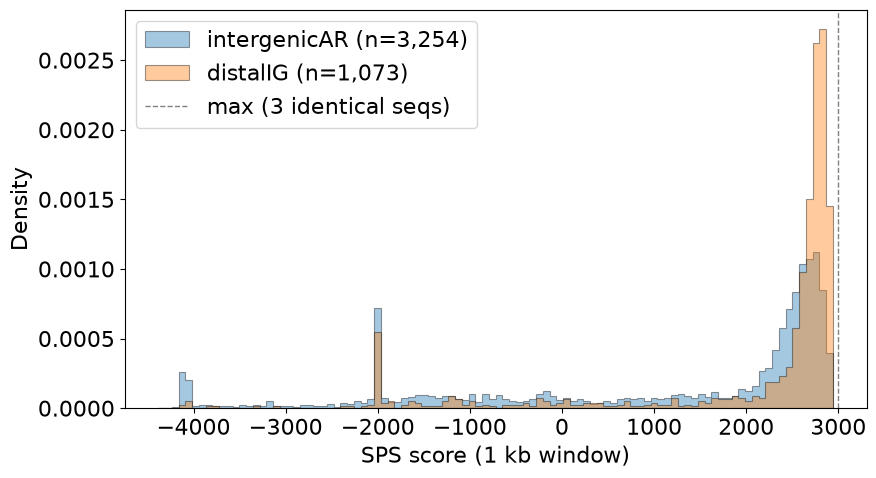

In [11]:
from matplotlib.font_manager import FontProperties

all_scores = np.concatenate(list(scores.values()))
bins = np.linspace(all_scores.min(), all_scores.max(), 101)
font_keys = (
    "font.size",
    "axes.titlesize",
    "axes.labelsize",
    "xtick.labelsize",
    "ytick.labelsize",
    "legend.fontsize",
    "figure.titlesize",
)
for key in font_keys:
    current_size = plt.rcParams[key]
    plt.rcParams[key] = FontProperties(size=current_size).get_size_in_points() + 2
    
fig, ax = plt.subplots(figsize=(9, 5))
for region in REGIONS:
    ax.hist(
        scores[region],
        bins=bins,
        density=True,
        histtype="stepfilled",
        alpha=0.4,
        edgecolor="black",
        linewidth=0.8,
        label=f"{region} (n={len(scores[region]):,})",
    )
ax.axvline(3 * WINDOW, color="grey", linestyle="--", linewidth=1, label="max (3 identical seqs)")
ax.set_xlabel(f"SPS score ({WINDOW // 1000} kb window)")
ax.set_ylabel("Density")
ax.legend()
fig.tight_layout()
fig.savefig("output_data/alignment_quality_sp_score_1kb.png", dpi=150)
plt.show()

Same data on a log-scaled y axis, which makes the long negative (gap-rich) tail visible.